In [ ]:
!pip install neurokit2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 696.5/696.5 kB 9.5 MB/s eta 0:00:00


In [ ]:
nk.ecg_simulate?

# Simular señales EKG en NeuroKit2

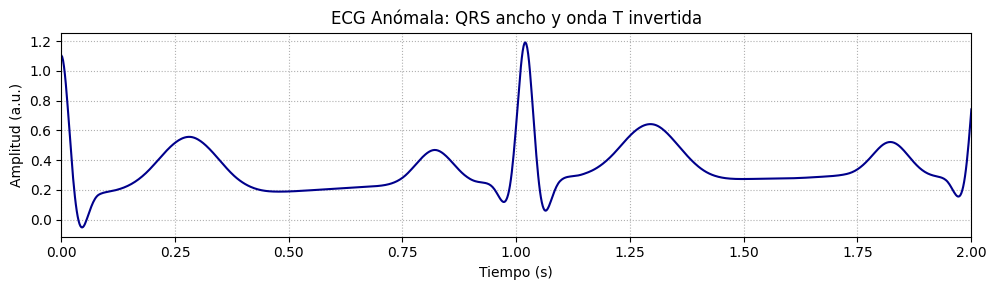

In [ ]:
# @title EKG sim 1
import neurokit2 as nk
import matplotlib.pyplot as plt
import numpy as np

# Simular 10 s de ECG con una frecuencia de 60 bpm
# y modificar amplitud y ancho de R y T para hacerlas más prominentes:
ecg_mod = nk.ecg_simulate(
    duration=10,
    sampling_rate=500,
    heart_rate=60,
    method="ecgsyn",
    # Ajustes de amplitudes (en unidades arbitrarias)
    a_P=0.01,   # onda P de pequeña amplitud
    a_Q=0.01,  # onda Q sutil
    a_R=1.0,   # pico R más alto
    a_S=0.05,  # onda S pequeña
    a_T=0.5,   # onda T moderadamente alta
    # Ajustes de anchos (duración de cada onda en segundos ≈ b*π/ sampling_rate)
    b_P=0.1,  # onda P algo ancha
    b_Q=0.2,
    b_R=0.03,  # complejo QRS algo más largo
    b_S=0.02,
    b_T=0.1    # onda T más extendida
)

# 2. Crear el eje de tiempo en segundos
fs = 500  # frecuencia de muestreo
n_samples = len(ecg_mod)
t = np.linspace(0, n_samples / fs, n_samples)

# 3. Graficar
plt.figure(figsize=(10, 3))
plt.plot(t, ecg_mod, color="darkblue")
plt.title("ECG Anómala: QRS ancho y onda T invertida")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (a.u.)")
plt.xlim(0, t[-1])
plt.tight_layout()
plt.xlim(0,2)
plt.grid(ls=":")
plt.show()

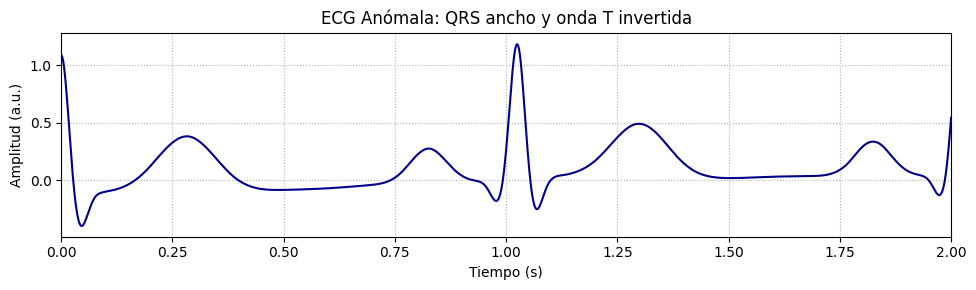

In [ ]:
# @title EKG sim 2
# Simular 10 segundos de ECG anómalo:
# - QRS ancho (b_R mayor) para simular bloqueos de rama
# - Onda T invertida (a_T negativa) para simular isquemia
ecg_abnormal = nk.ecg_simulate(
    duration=10,
    sampling_rate=500,
    heart_rate=60,
    method="ecgsyn",
    # Amplitudes: P leve, Q prominente, R normal, S moderada, T invertida
    a_P=0.1,
    a_Q=0.4,
    a_R=1.0,
    a_S=0.2,
    a_T=-0.5,
    # Anchos: P, Q y S normales, QRS ancho (b_R mayor), T algo ancho
    b_P=0.05,
    b_Q=0.02,
    b_R=0.06,
    b_S=0.02,
    b_T=0.1
)

# 2. Crear el eje de tiempo en segundos
fs = 500  # frecuencia de muestreo
n_samples = len(ecg_abnormal)
t = np.linspace(0, n_samples / fs, n_samples)

# 3. Graficar
plt.figure(figsize=(10, 3))
plt.plot(t, ecg_abnormal, color="darkblue")
plt.title("ECG Anómala: QRS ancho y onda T invertida")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (a.u.)")
plt.xlim(0, t[-1])
plt.tight_layout()
plt.xlim(0,2)
plt.grid(ls=":")
plt.show()


# Simular señales bipolares y unipolares

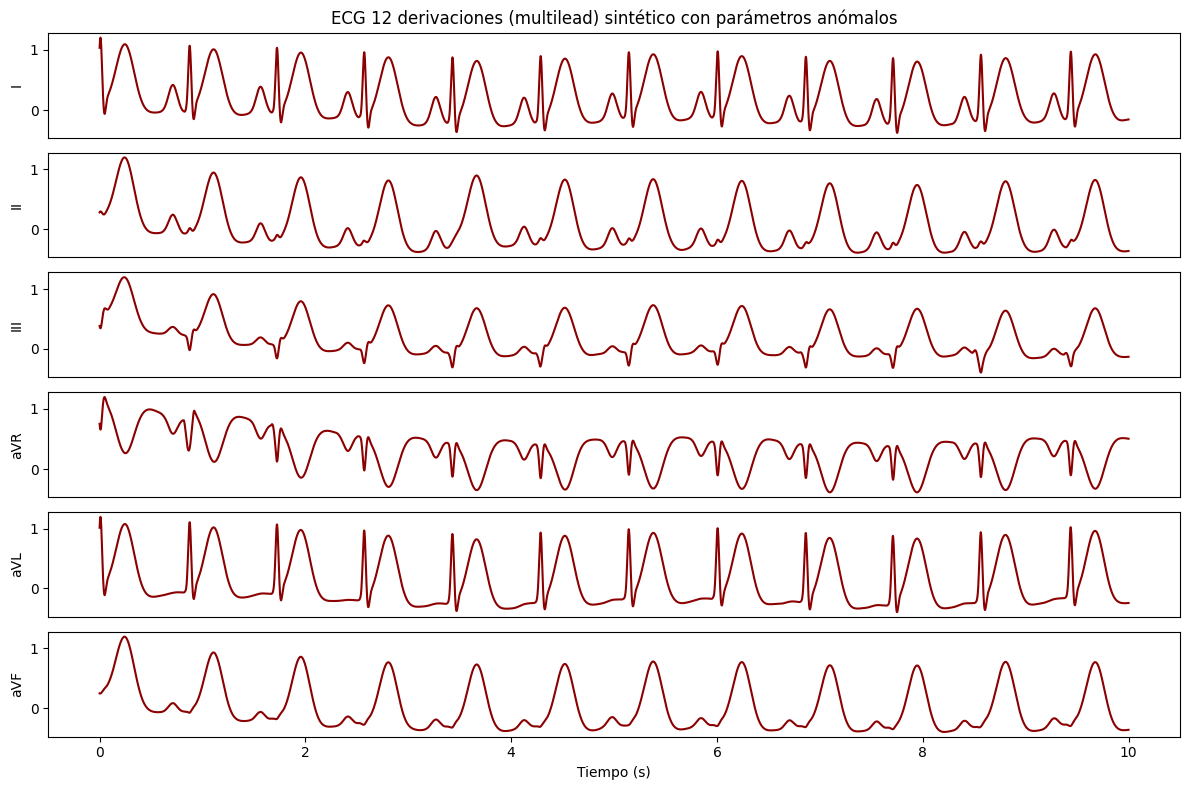

In [ ]:
# @title señal multilead
import numpy as np
import pandas as pd
import neurokit2 as nk
import matplotlib.pyplot as plt

# 1. Definir parámetros “normales” para un latido
ti = np.array((-70, -15,  0,  15, 100))   # θᵢ en grados
ai = np.array(( 1.2,  -5, 30, -7.5, 0.75)) # amplitudes
bi = np.array((0.25, 0.1, 0.1,  0.1, 0.4)) # anchos (std de cada gaussiana)

# 2. “Desordenar” esos parámetros para simular anomalías
ti = np.random.normal(ti, np.ones(5) * 3)
ai = np.random.normal(ai, np.abs(ai / 5))
bi = np.random.normal(bi, np.abs(bi / 5))

# 3. Generar el ECG multilead (12 derivaciones)
ecg12 = nk.ecg_simulate(
    duration=10,          # duración total en segundos
    sampling_rate=500,    # frecuencia de muestreo (Hz)
    heart_rate=70,        # frecuencia cardíaca media (lpm)
    method="multileads",  # usar modelo extendido de ECGSYN para 12 derivaciones
    ti=ti,                # parámetros angulares perturbados
    ai=ai,                # amplitudes perturbadas
    bi=bi                 # anchos perturbados
)

# 4. ecg12 es un DataFrame con 12 columnas: cada una es una derivación sintética.
#    Por defecto, se nombran ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6'].

# 5. Crear eje de tiempo (en segundos) para graficar
fs = 500
n_samples = len(ecg12)
t = np.linspace(0, n_samples / fs, n_samples)

# 6. Visualizar las seis primeras derivaciones (por ejemplo) en función del tiempo
plt.figure(figsize=(12, 8))
for i, lead in enumerate(ecg12.columns[:6], start=1):
    plt.subplot(6, 1, i)
    plt.plot(t, ecg12[lead], color="darkred")
    plt.ylabel(f"{lead}")
    if i == 1:
        plt.title("ECG 12 derivaciones (multilead) sintético con parámetros anómalos")
    if i < 6:
        plt.xticks([])

plt.xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()


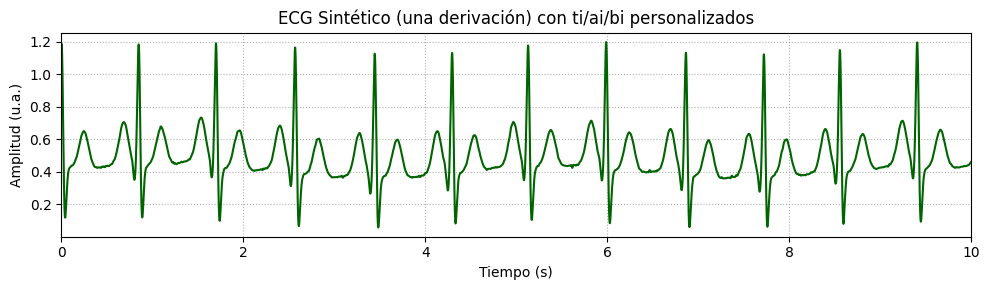

In [ ]:
# @title EKG simv2 1

# 1. Definir parámetros “normales” para un latido
#    (θᵢ en grados, amplitudes y anchos para cada onda P, Q, R, S, T)
ti = np.array((-70, -15,   0,   15,  100))
ai = np.array(( 1.2,  -5,  30,  -7.5,  0.75))
bi = np.array((0.25, 0.1, 0.1,  0.1,  0.4))

# 2. “Desordenar” (añadir ruido gaussiano) para simular anormalidades
ti = np.random.normal(ti, np.ones(5) * 3)
ai = np.random.normal(ai, np.abs(ai / 5))
bi = np.random.normal(bi, np.abs(bi / 5))

# 3. Generar el ECG de UNA sola derivación (“ecgsyn” devuelve un vector 1-D)
ecg_single = nk.ecg_simulate(
    duration=10,          # duración en segundos
    sampling_rate=1000,    # frecuencia de muestreo (Hz)
    heart_rate=70,        # latidos por minuto promedio
    method="ecgsyn",      # modelo ECGSYN para una sola derivación
    ti=ti,                # vectores con ruido
    ai=ai,
    bi=bi
)

# 4. Crear eje de tiempo en segundos
fs = 1000                                      # frecuencia de muestreo
n_samples = len(ecg_single)                   # debe ser 10 s × 500 Hz = 5000 muestras
t = np.linspace(0, n_samples / fs, n_samples)

# 5. Graficar ECG sintético en función del tiempo
plt.figure(figsize=(10, 3))
plt.plot(t, ecg_single, color="darkgreen")
plt.title("ECG Sintético (una derivación) con ti/ai/bi personalizados")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (u.a.)")
plt.xlim(0, t[-1])
plt.grid(ls=":")
plt.tight_layout()
plt.show()


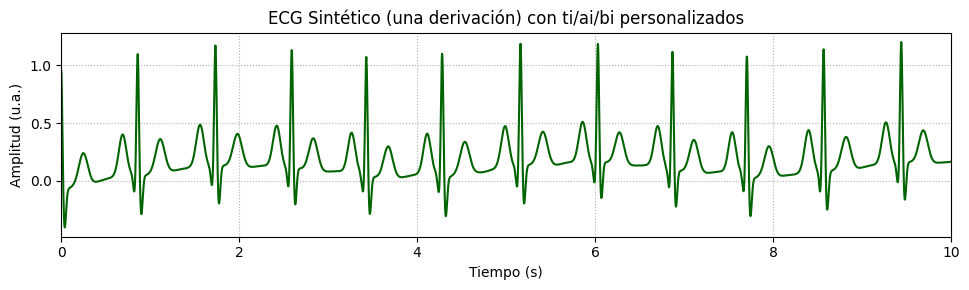

In [ ]:
# @title EKG simv2 2
ti = np.array((-70, -15,   0,   15,  100))
ai = np.array(( 1.2,  -5,  30,  -7.5,  0.75))
bi = np.array((0.25, 0.1, 0.1,  0.1,  0.4))

# 2. “Desordenar” (añadir ruido gaussiano) para simular anormalidades
ti = np.random.normal(ti, np.ones(5) * 3)
ai = np.random.normal(ai, np.abs(ai / 5))
bi = np.random.normal(bi, np.abs(bi / 5))

# 3. Generar el ECG de UNA sola derivación (“ecgsyn” devuelve un vector 1-D)
ecg_single = nk.ecg_simulate(
    duration=10,          # duración en segundos
    sampling_rate=500,    # frecuencia de muestreo (Hz)
    heart_rate=70,        # latidos por minuto promedio
    method="ecgsyn",      # modelo ECGSYN para una sola derivación
    ti=ti,                # vectores con ruido
    ai=ai,
    bi=bi
)

# 4. Crear eje de tiempo en segundos
fs = 500                                      # frecuencia de muestreo
n_samples = len(ecg_single)                   # debe ser 10 s × 500 Hz = 5000 muestras
t = np.linspace(0, n_samples / fs, n_samples)

# 5. Graficar ECG sintético en función del tiempo
plt.figure(figsize=(10, 3))
plt.plot(t, ecg_single, color="darkgreen")
plt.title("ECG Sintético (una derivación) con ti/ai/bi personalizados")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (u.a.)")
plt.xlim(0, t[-1])
plt.grid(ls=":")
plt.tight_layout()
plt.show()

# Extracción de caracteristicas clásicas

In [ ]:
from scipy.stats import skew, kurtosis

# Calcular características estadísticas
mean_ecg = np.mean(ecg_single)
median_ecg = np.median(ecg_single)
kurtosis_ecg = kurtosis(ecg_single)
skewness_ecg = skew(ecg_single)
energy_ecg = np.sum(ecg_single**2)

# Imprimir las características
print(f"Mean: {mean_ecg}")
print(f"Median: {median_ecg}")
print(f"Kurtosis: {kurtosis_ecg}")
print(f"Skewness: {skewness_ecg}")
print(f"Energy: {energy_ecg}")

Mean: 0.3230238215298666
Median: 0.2925699988355333
Kurtosis: 3.2484940271557257
Skewness: 0.9345675509800798
Energy: 722.3287628875995


# Ejemplo completo

In [ ]:
import warnings
warnings.filterwarnings('ignore')

=== DataFrame con características extraídas ===
    Signal_Type      Mean    Median       STD  Skewness   Kurtosis
0    ECG_Single  0.125064  0.060703  0.232681  1.673399   4.418664
1       ECG_Mod  0.003280 -0.040680  0.215700  3.316902  12.734335
2  ECG_Abnormal  0.265230  0.239737  0.259528  1.239556   3.714629

=== Resultados PCA (2 dimensiones) ===
        PC1       PC2   Signal_Type
0 -2.562970  0.178691    ECG_Single
1  5.912836 -0.015180       ECG_Mod
2 -3.349865 -0.163511  ECG_Abnormal


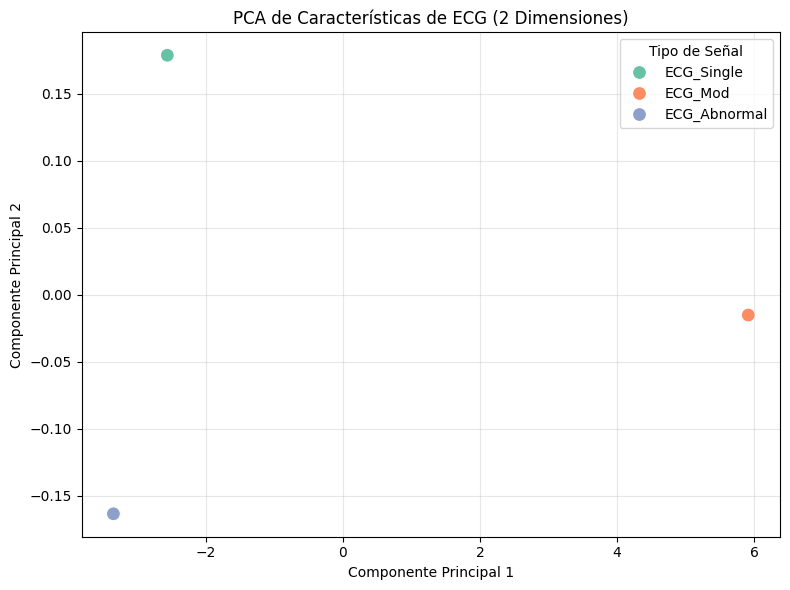

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis
from sklearn.decomposition import PCA
import neurokit2 as nk

# ------------------------------------------------------
# 1) GENERAR TRES SEÑALES DE ECG SINTÉTICAS
# ------------------------------------------------------

fs = 500  # frecuencia de muestreo (Hz)
duration = 10  # segundos

np.random.seed(42)  # Para reproducibilidad de los ruidos aleatorios

# (a) ECG “normal” (una sola derivación) mediante ecgsyn
ti0 = np.array((-70, -15, 0, 15, 100))
ai0 = np.array(( 1.2, -5, 30, -7.5, 0.75))
bi0 = np.array((0.25, 0.1,  0.1,  0.1,  0.4))

# Simulación 1: ECG “single” normal (sin turbear demasiado los parámetros)
ecg_single = nk.ecg_simulate(
    duration=duration,
    sampling_rate=fs,
    heart_rate=70,
    method="ecgsyn",
    ti = ti0,
    ai = ai0,
    bi = bi0
)

# (b) ECG “modificado” (ligera variación de amplitud y ancho)
# Para simular variaciones fisiológicas, añadimos ruido a ti, ai, bi:
ti1 = np.random.normal(ti0, np.ones(5) * 3)
ai1 = np.random.normal(ai0, np.abs(ai0/5))
bi1 = np.random.normal(bi0, np.abs(bi0/5))

ecg_mod = nk.ecg_simulate(
    duration=duration,
    sampling_rate=fs,
    heart_rate=70,
    method="ecgsyn",
    ti = ti1,
    ai = ai1,
    bi = bi1
)

# (c) ECG “anómalo” (QRS ancho + T invertida)
ti2 = np.random.normal(ti0, np.ones(5) * 3)
ai2 = np.random.normal(ai0, np.abs(ai0/5))
bi2 = np.random.normal(bi0, np.abs(bi0/5))
# Forcemos T invertida
ai2[4] = -0.5

# Forzamos QRS ancho aumentando bi2[2] (índice 2 corresponde a la onda R)
bi2[2] = bi2[2] * 2

ecg_abnormal = nk.ecg_simulate(
    duration=duration,
    sampling_rate=fs,
    heart_rate=70,
    method="ecgsyn",
    ti = ti2,
    ai = ai2,
    bi = bi2
)

# Ponerlas en una lista para iterar
ecg_signals = [ecg_single, ecg_mod, ecg_abnormal]
signal_names = ['ECG_Single', 'ECG_Mod', 'ECG_Abnormal']


# ------------------------------------------------------
# 2) EXTRAER CARACTERÍSTICAS DE CADA SEÑAL & ARMAR UN DF
# ------------------------------------------------------
all_features = []

for i, signal in enumerate(ecg_signals):
    # 2.1) Detectar picos R (para obtener RR)
    # Primero “limpiamos” un poco la señal (aunque ecg_simulate ya sale razonablemente limpio),
    # y luego usamos nk.ecg_peaks para localizar los índices de los R-peaks:
    ecg_cleaned = nk.ecg_clean(signal, sampling_rate=fs, method="biosppy")
    peaks_dict = nk.ecg_peaks(ecg_cleaned, sampling_rate=fs)
    #rpeaks = peaks_dict["ECG_R_Peaks"]  # índices de muestra donde NeuroKit2 detectó cada R
    rpeaks = peaks_dict[0]

    # 2.2) Calcular RR intervals en segundos
    if len(rpeaks) >= 2:
        t_peaks = rpeaks / fs
        rr_intervals = np.diff(t_peaks)  # array de (N_peaks - 1) valores en segundos
        rr_mean = np.mean(rr_intervals)
        rr_std  = np.std(rr_intervals)
    else:
        rr_mean = np.nan
        rr_std  = np.nan

    # 2.3) Estadísticos “básicos” + HOS
    feats = {
        'Signal_Type'       : signal_names[i],
        'Mean'              : np.mean(signal),
        'Median'            : np.median(signal),
        'STD'               : np.std(signal),
        'Skewness'          : skew(signal),
        'Kurtosis'          : kurtosis(signal, fisher=True),  # fisher=True => kurtosis “exceso” (gaussiana=0)
    #    'RR_Intervals_Mean' : rr_mean,
    #    'RR_Intervals_STD'  : rr_std
    }

    all_features.append(pd.DataFrame([feats]))

# Unir todo en un solo DataFrame
combined_features_df = pd.concat(all_features, ignore_index=True)

print("=== DataFrame con características extraídas ===")
print(combined_features_df)


# ------------------------------------------------------
# 3) HACER PCA DE 2 COMPONENTES SOBRE ESAS FEATURES
# ------------------------------------------------------

# 3.1) Preparamos los datos numéricos para PCA (quitamos la columna Signal_Type)
pca_input = combined_features_df.drop(columns=['Signal_Type']).copy()

# 3.1.1) Rellenar NaNs (por seguridad). Aquí se llenan con la media de cada columna.
pca_input = pca_input.fillna(pca_input.mean())

# 3.2) Instanciar y entrenar PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(pca_input)  # devuelve matrix (n_signals × 2)

# 3.3) Armamos un DataFrame para graficar
pca_df = pd.DataFrame(pca_result, columns=['PC1', 'PC2'])
pca_df['Signal_Type'] = combined_features_df['Signal_Type']

print("\n=== Resultados PCA (2 dimensiones) ===")
print(pca_df)


# ------------------------------------------------------
# 4) GRAFICAR RESULTADOS DEL PCA
# ------------------------------------------------------
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Signal_Type',
    data=pca_df,
    s=100,
    palette="Set2"
)
plt.title('PCA de Características de ECG (2 Dimensiones)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(alpha=0.3)
plt.legend(title='Tipo de Señal')
plt.tight_layout()
plt.show()